# 04 · El experimento principal en Home Credit

Este es el corazón del trabajo. Juntamos en el pool (el 30% que ningún modelo usó para entrenar) los scores de los cuatro modelos y corremos Conformal Selection 20 veces, partiendo el pool al azar en una mitad de calibración y otra de prueba. En cada corrida medimos a cuántos thin-file se aprueba y qué proporción de morosos hay entre los aprobados (FDR), calibrando por segmento y agrupado.

- **Lee:** `outputs/preds/xgboost_test.csv`, `gp_vars_test.csv`, `sngp_vars_test.csv` y `sngp_ensamble.npz`. Por eso hay que correrlo **después** del 05 y del 08.
- **Guarda:** `outputs/resultados_experimento.csv`, `outputs/tabla_T2.csv`, `outputs/tabla_T1.csv`, `outputs/tabla_regla_ingenua.csv` y las figuras `F2_aprobacion` y `F3_varianza` (esta última es de apoyo).
- **En el informe:** la Tabla 1 (Bloque 13), la Tabla 2 (Bloques 9 y 14), la Figura 2 (Bloque 10), el cociente 1,12 de la varianza de la SNGP (Bloque 11; la Figura 3 del informe es la de cajas del 10), el intervalo bootstrap de la sección 4.1 (Bloque 12) y la comparación con la regla ingenua de la sección 4.2 (Bloque 14).

In [1]:
# Bloque 7 (la numeración de bloques sigue la del 03). Armamos el pool del experimento.
# Conformal Selection necesita un número por solicitante donde más alto = mejor candidato para aprobar. Ese número es
# mu = probabilidad de BUEN pago = 1 - P(mora), o sea la ecuación (1) del informe. Acá lo calculamos para XGBoost y
# para el GP (y para un "GP ajustado" por su varianza, que es una prueba que no va al informe).
# Importante: el conformal no usa la probabilidad en sí, solo el ORDEN de los solicitantes. Por eso cualquier modelo
# sirve, y uno que ordena mejor aprueba a más gente con el mismo control de morosos.
# Los modelos se juntan cruzando por SK_ID_CURR (no por posición de fila), para estar seguros de que cada fila es el
# mismo solicitante en todos.

import numpy as np
import pandas as pd

from conformal import conformal_select

def score(logit,var=None,ajuste=False):
    """Devuelve mu = probabilidad de BUEN pago (más alto = mejor candidato).
    logit: logit de mora que predice el modelo (alto = más riesgo).
    var: varianza de esa predicción (solo la tienen el GP y la SNGP; XGBoost no).
    ajuste: interruptor. Si es True, achica el logit según la varianza (ajuste mean-field: logit / raíz(1 + pi/8 var)),
    o sea que a los solicitantes más inciertos los empuja hacia "no sé". Si es False, usa el logit tal cual."""
    z=logit / np.sqrt(1+np.pi/8*var) if ajuste else logit
    return 1 - 1 / (1 + np.exp(-z))   # la sigmoide de z es la prob. de mora; 1 menos eso es la prob. de buen pago (mu)

xgb=pd.read_csv("outputs/preds/xgboost_test.csv")
gpv=pd.read_csv("outputs/preds/gp_vars_test.csv")

pool=xgb[["SK_ID_CURR", "thin_file", "TARGET"]].copy()
pool["mu_xgb"]=score(xgb["logit"].to_numpy())
pool = pool.merge(gpv[["SK_ID_CURR", "logit", "var"]], on="SK_ID_CURR", how="inner")   # pegamos el GP por ID
pool["mu_gp"] = score(pool["logit"].to_numpy())
pool["mu_gp_aj"] = score(pool["logit"].to_numpy(), pool["var"].to_numpy(),
                         ajuste=True)   # el GP ajustado por varianza (prueba, no va al informe)


print("filas del pool:", len(pool), "| thin-file:", int(pool["thin_file"].sum()))
print(pool[["mu_xgb", "mu_gp", "mu_gp_aj"]].describe().round(4))

# Pool de 92.254 solicitantes, 13.206 thin-file. El mu medio es ~0,92 en los tres, o sea ~1 menos la mora (8,1%).
# El GP es menos extremo que XGBoost (mínimo 0,349 contra 0,258), consistente con que ve 20 variables y no 200.
# mu_gp_aj es casi igual a mu_gp: la varianza del GP (~0,01) apenas mueve el logit.

filas del pool: 92254 | thin-file: 13206
           mu_xgb       mu_gp    mu_gp_aj
count  92254.0000  92254.0000  92254.0000
mean       0.9189      0.9170      0.9165
std        0.0785      0.0761      0.0762
min        0.2583      0.3491      0.3497
25%        0.8967      0.8917      0.8911
50%        0.9460      0.9430      0.9425
75%        0.9702      0.9690      0.9686
max        0.9979      0.9964      0.9962


In [2]:
# Sumamos al pool la SNGP (notebook 05) y el ensamble de 5 SNGP (notebook 08).
# De la SNGP usamos el logit sin ajuste por varianza (lambda = 0), que fue lo que eligió la validación en el 05:
# penalizar por varianza solo bajaba la aprobación thin-file.
# Del ensamble usamos el promedio de los logits de las 5 redes. El .npz guarda las filas en el mismo orden que
# ids_test.csv (= orden de X_test), así que le pegamos el ID y cruzamos por SK_ID_CURR como al resto.

sngp = pd.read_csv("outputs/preds/sngp_vars_test.csv")   # columnas: SK_ID_CURR, logit, var
sngp = sngp.rename(columns={"logit": "logit_sngp", "var": "var_sngp"})
pool = pool.merge(sngp, on="SK_ID_CURR", how="inner")   # pega columnas por ID de solicitante
pool["mu_sngp"] = score(pool["logit_sngp"].to_numpy())   # prob. de buen pago según la SNGP

ens = np.load("outputs/preds/sngp_ensamble.npz")   # lg_po = logits del pool, una fila por red (5 x 92254)
ids_po = pd.read_csv("outputs/ids_test.csv")["SK_ID_CURR"].to_numpy()
ens_df = pd.DataFrame({"SK_ID_CURR": ids_po, "logit_ens": ens["lg_po"].mean(0)})   # mean(0) = promedio entre las 5 redes
pool = pool.merge(ens_df, on="SK_ID_CURR", how="inner")
pool["mu_ens"] = score(pool["logit_ens"].to_numpy())   # prob. de buen pago según el ensamble

print("filas del pool:", len(pool))   # tiene que seguir dando 92254
print(pool[["mu_xgb", "mu_gp", "mu_sngp", "mu_ens"]].describe().round(4))

# Siguen siendo 92.254 filas (ningún ID se perdió en los merge). mu medio SNGP 0,9169 y ensamble 0,9193, parecidos a
# XGBoost (0,9189).

filas del pool: 92254
           mu_xgb       mu_gp     mu_sngp      mu_ens
count  92254.0000  92254.0000  92254.0000  92254.0000
mean       0.9189      0.9170      0.9169      0.9193
std        0.0785      0.0761      0.0798      0.0776
min        0.2583      0.3491      0.3856      0.3943
25%        0.8967      0.8917      0.8918      0.8953
50%        0.9460      0.9430      0.9452      0.9471
75%        0.9702      0.9690      0.9712      0.9722
max        0.9979      0.9964      0.9954      0.9957


In [3]:
# Bloque 8. El experimento. Para cada modelo y cada nivel alfa, la pregunta es: ¿a cuántos solicitantes puedo aprobar
# sin que la proporción de morosos entre los aprobados (FDR) pase de alfa, en promedio? Lo repetimos 20 veces con
# cortes al azar distintos del pool. En cada repetición:
#   (1) partimos el pool 50/50 en calibración y prueba, estratificando por segmento x TARGET para que las dos mitades
#       tengan la misma mezcla;
#   (2) con la mitad de calibración, conformal_select arma los p-valores (ecuación 2 del informe) y Benjamini-Hochberg
#       decide a quién aprobar (ecuación 3);
#   (3) como en la mitad de prueba sí sabemos quién fue moroso, medimos la FDR realizada y la tasa de aprobación.
# Hay dos versiones: POR SEGMENTO (thin-file y resto se calibran cada uno con sus propios morosos) y AGRUPADA (se
# calibra con todos juntos y después se mira cada segmento). La teoría dice que la garantía vale para el conjunto que
# se calibra: por segmento vale dentro de thin-file; agrupada vale en el total, pero no tiene por qué valer adentro
# de un subgrupo.
# El "GP ajustado" queda en MODELOS aunque no va al informe: si lo sacáramos, cambiarían los números aleatorios que
# usan la SNGP y el ensamble (van después en el loop) y sus resultados se moverían un poquito.
# El ensamble va último por lo mismo: así los otros modelos usan exactamente los mismos sorteos que antes de sumarlo.

from sklearn.model_selection import train_test_split

R = 20   # cantidad de repeticiones (particiones distintas del pool)
ALFAS = {"thin": [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09],
         "resto": [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07]}
ALFAS_AGRUPADA = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07]
MODELOS = {"XGBoost": "mu_xgb", "GP": "mu_gp", "GP ajustado": "mu_gp_aj", "SNGP": "mu_sngp",
           "Ensamble": "mu_ens"}

y = pool["TARGET"].to_numpy()
thin = pool["thin_file"].to_numpy().astype(bool)
estrato = 2 * thin + y   # 0 resto pagador, 1 resto moroso, 2 thin pagador, 3 thin moroso


def metricas(aprobado, y_test):
    """Resume una decisión de aprobación.
    aprobado: vector True/False de a quién se aprobó.
    y_test: TARGET real de esos mismos solicitantes (1 = moroso).
    Devuelve aprobados, morosos aprobados, FDR realizada (morosos / aprobados), tasa de aprobación y potencia
    (qué parte de los buenos pagadores se aprobó)."""
    n_aprob = int(aprobado.sum())
    morosos = int((aprobado & (y_test == 1)).sum())
    buenos = int((aprobado & (y_test == 0)).sum())
    return {"aprobados": n_aprob, "morosos_aprobados": morosos,
            "fdr": morosos / max(n_aprob, 1),   # max(.,1) evita dividir por cero si no se aprueba a nadie
            "tasa_aprob": n_aprob / len(y_test),
            "potencia": buenos / max(int((y_test == 0).sum()), 1)}


filas = []
for r in range(R):
    i_cal, i_test = train_test_split(np.arange(len(pool)), test_size=0.5,
                                     stratify=estrato, random_state=r)
    rng = np.random.default_rng(r)   # para los desempates aleatorios del p-valor (la U de la ecuación 2)
    for modelo, col in MODELOS.items():
        mu = pool[col].to_numpy()
        # (a) Por segmento: cada segmento se calibra con sus propios morosos
        for seg, es_thin in [("thin", True), ("resto", False)]:
            c = i_cal[thin[i_cal] == es_thin]   # calibración de este segmento
            t = i_test[thin[i_test] == es_thin]   # prueba de este segmento
            for alfa in ALFAS[seg]:
                aprob = conformal_select(mu[c], y[c], mu[t], alfa, rng)
                filas.append({"r": r, "modelo": modelo, "version": "por segmento",
                              "segmento": seg, "alfa": alfa, **metricas(aprob, y[t])})
        # (b) Agrupada: se calibra con todos juntos y después se mira cada segmento por separado
        for alfa in ALFAS_AGRUPADA:
            aprob = conformal_select(mu[i_cal], y[i_cal], mu[i_test], alfa, rng)
            for seg, m in [("thin", thin[i_test]), ("resto", ~thin[i_test]),
                           ("total", np.ones(len(i_test), bool))]:
                filas.append({"r": r, "modelo": modelo, "version": "agrupada",
                              "segmento": seg, "alfa": alfa, **metricas(aprob[m], y[i_test][m])})
    print("partición", r, "lista")

res = pd.DataFrame(filas)
res.to_csv("outputs/resultados_experimento.csv", index=False)
print(res.shape)

# res tiene 3700 filas = 20 repeticiones x 5 modelos x 37 filas por modelo (16 por segmento + 21 de la agrupada,
# que tiene 7 alfas x 3 segmentos). Guardado en outputs/resultados_experimento.csv.

partición 0 lista


partición 1 lista


partición 2 lista


partición 3 lista


partición 4 lista


partición 5 lista


... (10 outputs left out)

partición 16 lista


partición 17 lista


partición 18 lista


partición 19 lista
(3700, 10)


In [4]:
# Bloque 9. Promediamos las 20 repeticiones por modelo, versión, segmento y alfa, y guardamos la tabla T2 (de acá
# salen las columnas de aprobación y de FDR por segmento y agrupada de la Tabla 2 del informe). Miramos tres cosas:
# 1) la garantía: la FDR promedio no debería pasar de alfa (salvo ruido chico). Es el chequeo de que el método anda;
# 2) lo principal: la tasa de aprobación thin-file calibrando por segmento. Más alta = el modelo aprueba a más gente
#    con el mismo control de morosos;
# 3) la versión agrupada mirando la FDR dentro de thin-file, que es la comparación que justifica calibrar por segmento.

resumen = (res.groupby(["modelo", "version", "segmento", "alfa"])
              .agg(fdr_media=("fdr", "mean"), fdr_desvio=("fdr", "std"),
                   tasa_media=("tasa_aprob", "mean"), tasa_desvio=("tasa_aprob", "std"),
                   potencia_media=("potencia", "mean"))
              .reset_index())
resumen.to_csv("outputs/tabla_T2.csv", index=False)

# chequeo de la garantía: la FDR media no debería pasar de alfa (salvo ruido de ~0,005)
validas = resumen[(resumen["version"] == "por segmento") | (resumen["segmento"] == "total")]
exceso = validas["fdr_media"] - validas["alfa"]
print("Mayor exceso de FDR media sobre alfa (donde vale la garantía):", round(exceso.max(), 4))

# lo principal: tasa de aprobación thin-file, por segmento
vista = resumen[(resumen["version"] == "por segmento") & (resumen["segmento"] == "thin")]
print(vista.pivot(index="alfa", columns="modelo", values="tasa_media").round(3))

# la versión agrupada: FDR dentro de thin-file (acá la garantía NO tiene por qué valer)
vista = resumen[(resumen["version"] == "agrupada") & (resumen["segmento"] == "thin")]
print(vista.pivot(index="alfa", columns="modelo", values="fdr_media").round(4))

# Garantía: el mayor exceso de FDR media sobre alfa es 0,0021, o sea que se cumple (es ruido de 20 repeticiones).
# Aprobación thin-file a alfa 3 / 5 / 7 / 9%: XGBoost 28,9 / 54,4 / 80,4 / 95,6% | ensamble 26,7 / 54,2 / 78,6 / 95,4%
# | SNGP 22,6 / 52,1 / 78,3 / 95,4% | GP 16,1 / 49,7 / 78,4 / 94,5%. XGBoost aprueba igual o más que todos en todos
# los alfas, el ensamble queda segundo y el GP último (Tabla 2 y Figura 2 del informe).
# Agrupada: desde alfa 3%, la FDR dentro de thin-file se pasa de alfa en todos los modelos. A alfa 5%: 6,4% XGBoost,
# 6,5% ensamble, 6,7% SNGP y 7,2% GP (columna "Agrupada" de la Tabla 2). La intuición: calibrando todo junto, la
# garantía es sobre el TOTAL de aprobados. Los thin-file son más riesgosos (10,1% de mora) y sus aprobados quedan más
# cerca del corte, así que dentro de thin-file la proporción de morosos se pasa de alfa, mientras que en el resto
# queda por debajo y el promedio total igual cumple. Por eso, si lo que nos importa es thin-file, hay que calibrarlo
# con sus propios morosos.

Mayor exceso de FDR media sobre alfa (donde vale la garantía): 0.0021
modelo  Ensamble     GP  GP ajustado   SNGP  XGBoost
alfa                                                
0.01       0.003  0.012        0.012  0.001    0.011
0.02       0.080  0.050        0.049  0.029    0.153
0.03       0.267  0.161        0.162  0.226    0.289
0.04       0.396  0.335        0.346  0.385    0.414
0.05       0.542  0.497        0.499  0.521    0.544
0.06       0.655  0.628        0.629  0.662    0.687
0.07       0.786  0.784        0.784  0.783    0.804
0.08       0.895  0.879        0.878  0.891    0.895
0.09       0.954  0.945        0.945  0.954    0.956
modelo  Ensamble      GP  GP ajustado    SNGP  XGBoost
alfa                                                  
0.01      0.0071  0.0101       0.0101  0.0112   0.0106
0.02      0.0227  0.0295       0.0296  0.0251   0.0201
0.03      0.0370  0.0443       0.0442  0.0400   0.0346
0.04      0.0510  0.0598       0.0598  0.0537   0.0498
0.05      0.0654 

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


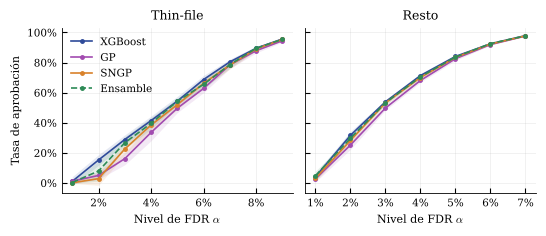

In [5]:
# Bloque 10. Figura 2 del informe (F2): tasa de aprobación contra alfa, un panel para thin-file y otro para el resto.
# Una curva por modelo (XGBoost, GP, SNGP y ensamble) con el promedio de las 20 repeticiones y una banda de ±1 desvío
# entre repeticiones. Se lee como "¿a cuánta gente apruebo si acepto alfa% de morosos?": curva más alta = mejor
# modelo. Si dos bandas se pisan, la diferencia puede ser ruido. El GP ajustado no se dibuja (es casi igual al GP).
import matplotlib.pyplot as plt
from estilo import *                          # paleta azul-violeta y estilo común (ver estilo.py)
from matplotlib.ticker import PercentFormatter   # para escribir 0.05 como "5%"

DIBUJAR = ["XGBoost", "GP", "SNGP", "Ensamble"]

fig, ejes = plt.subplots(1, 2, figsize=(6.0, 2.6), sharey=True)  # 1 fila, 2 paneles; tamaño en pulgadas; mismo eje y
for ax, seg, titulo in [(ejes[0], "thin", "Thin-file"), (ejes[1], "resto", "Resto")]:  # un panel por segmento
    for modelo in DIBUJAR:                                          # una curva por modelo
        d = resumen[(resumen["version"] == "por segmento") & (resumen["segmento"] == seg)
                    & (resumen["modelo"] == modelo)]               # filas de la tabla T2 de este panel y modelo
        relleno = COLORES[modelo] if RELLENO[modelo] else "white"   # el ensamble va con marcador hueco para distinguirlo
        ax.plot(d["alfa"], d["tasa_media"], ESTILOS[modelo], color=COLORES[modelo],
                linewidth=2.0 if modelo == "XGBoost" else 1.2,      # XGBoost (la vara) un poco más grueso
                marker=MARCAS[modelo], markersize=4, markerfacecolor=relleno, markeredgecolor=COLORES[modelo],
                markeredgewidth=0.9, label=modelo, zorder=3 if modelo == "XGBoost" else 2)
        ax.fill_between(d["alfa"], d["tasa_media"] - d["tasa_desvio"], d["tasa_media"] + d["tasa_desvio"],
                        color=COLORES[modelo], alpha=0.07, linewidth=0)   # banda: media -/+ un desvío entre repeticiones
    ax.set_title(titulo)                                            # título del panel
    ax.set_xlabel(r"Nivel de FDR $\alpha$")                         # etiqueta del eje x (con la letra alfa)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))   # eje x en porcentaje (1 = 100%, sin decimales)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))   # eje y en porcentaje
ejes[0].set_ylabel("Tasa de aprobación")                            # el eje y solo se rotula a la izquierda
ejes[0].legend(frameon=False, loc="upper left", handlelength=2.4)                     # leyenda sin marco, arriba a la izquierda
fig.tight_layout()                                                  # acomoda para que nada se pise
fig.savefig("outputs/F2_aprobacion.pdf", bbox_inches="tight")       # versión vectorial para el informe
fig.savefig("outputs/F2_aprobacion.png", dpi=300, bbox_inches="tight")  # versión imagen, 300 puntos por pulgada
plt.show()                                                          # mostrarla en el notebook

# En thin-file la curva de XGBoost va arriba de todas, sobre todo con alfa bajo (2-4%), y a partir de alfa ~7-9% las
# cuatro se juntan. En el resto las curvas casi se pisan. Guardada en outputs/F2_aprobacion.pdf/.png.

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


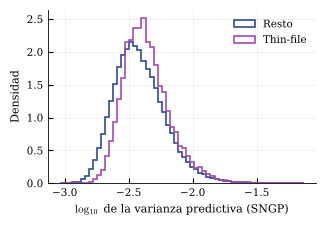

mediana de la varianza, thin-file / resto: 1.12


In [7]:
# Bloque 11. Figura de apoyo (F3_varianza; en el informe la reemplaza la Figura 3 de cajas, del 10): histograma (solo el contorno) del log de la varianza de la SNGP, una curva
# para thin-file y otra para el resto. Es la prueba visual de la hipótesis: si la red viera a los thin-file como
# "lejanos", su curva estaría corrida a la derecha (más varianza). Usamos log10 porque la varianza cambia por órdenes
# de magnitud. Al final imprime el cociente de medianas thin-file / resto.
log_var = np.log10(pool["var_sngp"].to_numpy())   # log10 de la varianza SNGP de cada solicitante
bins = np.linspace(log_var.min(), log_var.max(), 61)  # 60 intervalos iguales, mismos para ambas curvas

fig, ax = plt.subplots(figsize=(3.3, 2.3))        # un solo panel, ancho de media columna
for es_thin, nombre, color in [(False, "Resto", COLOR_RESTO), (True, "Thin-file", COLOR_THIN)]:
    ax.hist(log_var[thin == es_thin],             # solo los solicitantes de este segmento
            bins=bins,                            # los mismos intervalos
            density=True,                         # área = 1: se pueden comparar segmentos de distinto tamaño
            histtype="step",                      # solo el contorno, sin relleno
            color=color, linewidth=1.2, label=nombre)
ax.set_xlabel(r"$\log_{10}$ de la varianza predictiva (SNGP)")
ax.set_ylabel("Densidad")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("outputs/F3_varianza.pdf", bbox_inches="tight")             # versión vectorial
fig.savefig("outputs/F3_varianza.png", dpi=300, bbox_inches="tight")    # versión imagen
plt.show()

print("mediana de la varianza, thin-file / resto:",
      round(float(np.median(pool["var_sngp"][thin]) / np.median(pool["var_sngp"][~thin])), 2))  # cociente de medianas

# Las dos curvas están casi superpuestas; la de thin-file apenas corrida a la derecha. Cociente de medianas
# thin-file / resto = 1,12: la red casi no ve a los thin-file como más lejanos que el resto. Es el 1,12 de la sección
# 4.1 y de la Figura 3 de cajas. Guardada en outputs/F3_varianza.pdf/.png.

In [8]:
# Bloque 12. Bootstrap pareado: ¿la diferencia de AUC en thin-file entre XGBoost y cada modelo es real o es ruido?
# Remuestreamos los thin-file del pool con reposición, calculamos los AUC sobre las MISMAS personas en cada remuestra
# y miramos cómo se distribuye la diferencia. "Pareado" quiere decir justamente eso: las dos AUC de cada diferencia
# salen de la misma remuestra, así no mezclamos el ruido de remuestrear con la diferencia real entre modelos.
# Si el intervalo del 95% no incluye el 0, la diferencia es significativa.

from sklearn.metrics import roc_auc_score

d = pool[pool["thin_file"].astype(bool)]   # solo los thin-file del pool
y_t = d["TARGET"].to_numpy()
s_xgb = -d["mu_xgb"].to_numpy()   # signo menos: el AUC necesita un score de riesgo (alto = moroso), y mu es de buen pago
otros = {"GP": -d["mu_gp"].to_numpy(), "SNGP": -d["mu_sngp"].to_numpy(), "Ensamble": -d["mu_ens"].to_numpy()}

rng = np.random.default_rng(42)
B = 2000   # cantidad de remuestras bootstrap
remuestras = [rng.integers(0, len(y_t), len(y_t)) for _ in range(B)]   # índices sorteados con reposición (las mismas para todos)

print("AUC thin pool  XGBoost:", round(roc_auc_score(y_t, s_xgb), 4))
for nombre, s in otros.items():
    dif = np.array([roc_auc_score(y_t[i], s_xgb[i]) - roc_auc_score(y_t[i], s[i]) for i in remuestras])
    print(f"{nombre}: AUC {roc_auc_score(y_t, s):.4f} | diferencia XGB - {nombre}: {dif.mean():.4f}",
          "| IC 95%:", np.round(np.percentile(dif, [2.5, 97.5]), 4))

# AUC thin-file en el pool: XGBoost 0,7203 | GP 0,6996 (diferencia 0,0207, IC [0,0138; 0,0272]) | SNGP 0,7091
# (0,0113, IC [0,0053; 0,0172]) | ensamble 0,7126 (0,0077, IC [0,0020; 0,0130]).
# Ningún intervalo incluye el 0: XGBoost ordena significativamente mejor a los thin-file que los tres. La red le gana
# al GP y el ensamble achica la brecha con XGBoost a casi la mitad. En el informe va como "ensamble menos XGBoost =
# −0,0077, IC [−0,013; −0,002]" (es la misma cuenta con el signo dado vuelta).

AUC thin pool  XGBoost: 0.7203


GP: AUC 0.6996 | diferencia XGB - GP: 0.0207 | IC 95%: [0.0138 0.0272]


SNGP: AUC 0.7091 | diferencia XGB - SNGP: 0.0113 | IC 95%: [0.0053 0.0172]


Ensamble: AUC 0.7126 | diferencia XGB - Ensamble: 0.0077 | IC 95%: [0.002 0.013]


In [9]:
# Bloque 13. Tabla 1 del informe (T1): qué tan bien predice cada modelo en el pool, por segmento. Tres medidas:
# AUC (¿ordena bien a morosos y pagadores?), log-loss (¿qué tan buenas son las probabilidades?) y ECE (¿están
# calibradas? o sea, cuando el modelo dice "10% de mora", ¿termina en mora el 10%?).
# El conformal solo usa el orden, así que el AUC es lo que decide cuántos thin-file se aprueban; log-loss y ECE miran
# otra cosa, y un modelo puede ordenar bien y estar mal calibrado (o al revés).
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, log_loss

# Cargamos los archivos del pool y los unimos por SK_ID_CURR
xgb = pd.read_csv("outputs/preds/xgboost_test.csv")             # trae thin_file, TARGET y el logit de XGBoost
gp = pd.read_csv("outputs/preds/gp_vars_test.csv")[["SK_ID_CURR", "logit"]].rename(columns={"logit": "logit_gp"})
sn = pd.read_csv("outputs/preds/sngp_vars_test.csv")[["SK_ID_CURR", "logit"]].rename(columns={"logit": "logit_sngp"})
d = (xgb.rename(columns={"logit": "logit_xgb"})[["SK_ID_CURR", "thin_file", "TARGET", "logit_xgb"]]
        .merge(gp, on="SK_ID_CURR").merge(sn, on="SK_ID_CURR").merge(ens_df, on="SK_ID_CURR"))  # ens_df viene del Bloque 7
print("filas del pool:", len(d))                                 # tiene que dar 92254


def ece(p, y, bins=10):
    """Error de calibración esperado: promedio ponderado de |prob. media predicha - tasa real|.
    p: probabilidades predichas de default. y: 0/1 reales. bins: cantidad de grupos
    de igual tamaño (por cuantiles, porque casi todas las p son chicas)."""
    cortes = np.quantile(p, np.linspace(0, 1, bins + 1))          # bordes de los grupos
    grupo = np.clip(np.searchsorted(cortes, p, side="right") - 1, 0, bins - 1)  # a qué grupo cae cada p
    total = 0.0
    for b in range(bins):
        m = grupo == b
        if m.any():
            total += m.mean() * abs(p[m].mean() - y[m].mean())    # peso del grupo x brecha
    return total


filas = []
y_all = d["TARGET"].to_numpy()
thin = d["thin_file"].to_numpy().astype(bool)
for nombre, col in [("XGBoost", "logit_xgb"), ("GP", "logit_gp"), ("SNGP", "logit_sngp"), ("Ensamble", "logit_ens")]:
    p_all = 1 / (1 + np.exp(-d[col].to_numpy()))                  # logit -> probabilidad de default
    for seg, m in [("Total", np.ones(len(d), bool)), ("Thin-file", thin), ("Resto", ~thin)]:
        p, y = np.clip(p_all[m], 1e-6, 1 - 1e-6), y_all[m]
        filas.append({"Modelo": nombre, "Segmento": seg, "AUC": roc_auc_score(y, p),
                      "Log-loss": log_loss(y, p), "ECE": ece(p, y)})

T1 = pd.DataFrame(filas)
T1_vista = T1.pivot(index="Modelo", columns="Segmento", values=["AUC", "Log-loss", "ECE"]).round(4)
T1_vista = T1_vista.reindex(["XGBoost", "GP", "SNGP", "Ensamble"])
print(T1_vista.to_string())
T1.round(4).to_csv("outputs/tabla_T1.csv", index=False)
print("guardado: outputs/tabla_T1.csv")

# AUC thin-file: XGBoost 0,7203, ensamble 0,7126, SNGP 0,7091, GP 0,6996 (el mismo orden en total y en el resto).
# Log-loss thin-file: XGBoost 0,2979 es el mejor y el GP 0,3061 el peor.
# ECE: todos chicos (< 0,02). XGBoost es el mejor calibrado (0,0039 en thin-file) y el GP el peor (0,0196). Esa
# diferencia de calibración es la que hace fallar a la regla ingenua con el GP en el bloque que sigue.
# Guardada en outputs/tabla_T1.csv.

filas del pool: 92254


             AUC                   Log-loss                       ECE                  
Segmento   Resto Thin-file   Total    Resto Thin-file   Total   Resto Thin-file   Total
Modelo                                                                                 
XGBoost   0.7560    0.7203  0.7523   0.2392    0.2979  0.2476  0.0015    0.0039  0.0017
GP        0.7442    0.6996  0.7370   0.2427    0.3061  0.2518  0.0061    0.0196  0.0039
SNGP      0.7522    0.7091  0.7471   0.2405    0.3013  0.2492  0.0044    0.0080  0.0039
Ensamble  0.7535    0.7126  0.7490   0.2399    0.3002  0.2486  0.0025    0.0078  0.0030
guardado: outputs/tabla_T1.csv


In [10]:
# Bloque 14. ¿Qué aporta Conformal Selection frente a una regla "ingenua"? (sección 4.2 y Tabla 2 del informe)
# La regla ingenua es lo que haría cualquiera sin conformal: creerle al modelo. Ordena a los thin-file de menor a
# mayor probabilidad de mora predicha p̂ y aprueba a los k primeros, con el k más grande tal que el PROMEDIO de p̂
# entre los aprobados no pase de alfa: k = máx{k : (1/k) Σ_{l<=k} p̂_(l) <= alfa}. Si el modelo está bien calibrado,
# ese promedio es la mora esperada entre los aprobados y la regla cumple; si el modelo subestima el riesgo, aprueba
# de más y se pasa. Conformal Selection, en cambio, no usa el valor de p̂ sino solo el orden (lo compara contra los
# morosos reales de calibración), así que su garantía no depende de la calibración.
# La regla ingenua no necesita calibración, así que la aplicamos a todos los thin-file del pool de una vez.
# Al final armamos la Tabla 2 del informe tal cual: aprobación por segmento a alfa 3/5/7%, y FDR a alfa 5% por
# segmento, agrupada e ingenua.

ALFA_TABLA = 0.05
d = pool[pool["thin_file"].astype(bool)]   # los 13.206 thin-file del pool
y_t = d["TARGET"].to_numpy()
print("mora real de los thin-file del pool:", round(y_t.mean(), 4))


def regla_ingenua(p, alfa):
    """Aprueba a los de menor riesgo predicho mientras el riesgo predicho PROMEDIO de los aprobados no pase de alfa.
    p: probabilidad de mora predicha por el modelo para cada solicitante.
    alfa: proporción de morosos que se tolera.
    Devuelve un vector True/False (True = aprobado)."""
    orden = np.argsort(p)   # del más seguro al más riesgoso
    promedio = np.cumsum(p[orden]) / np.arange(1, len(p) + 1)   # riesgo predicho promedio de los k primeros, para cada k
    cumplen = np.nonzero(promedio <= alfa)[0]
    k = cumplen.max() + 1 if len(cumplen) else 0   # el k más grande que cumple (0 si ninguno)
    aprobado = np.zeros(len(p), dtype=bool)
    aprobado[orden[:k]] = True
    return aprobado


filas_ing = []
for modelo, col in [("XGBoost", "mu_xgb"), ("Ensamble", "mu_ens"), ("SNGP", "mu_sngp"), ("GP", "mu_gp")]:
    p = 1 - d[col].to_numpy()   # mu es la prob. de buen pago, así que 1 - mu es la prob. de mora predicha
    a = regla_ingenua(p, ALFA_TABLA)
    filas_ing.append({"modelo": modelo, "mora predicha media": p.mean(), "aprobación ingenua": a.mean(),
                      "FDR ingenua": y_t[a].mean()})
ingenua = pd.DataFrame(filas_ing).set_index("modelo")
ingenua.round(4).to_csv("outputs/tabla_regla_ingenua.csv")
print(ingenua.round(4).to_string())

# La Tabla 2 del informe, armada desde la tabla T2 (Bloque 9) y la regla ingenua
seg = resumen[(resumen["version"] == "por segmento") & (resumen["segmento"] == "thin")]
agr = resumen[(resumen["version"] == "agrupada") & (resumen["segmento"] == "thin")]
tabla2 = pd.DataFrame({
    "aprob. 3%": seg[seg["alfa"] == 0.03].set_index("modelo")["tasa_media"],
    "aprob. 5%": seg[seg["alfa"] == 0.05].set_index("modelo")["tasa_media"],
    "aprob. 7%": seg[seg["alfa"] == 0.07].set_index("modelo")["tasa_media"],
    "FDR 5% por segmento": seg[seg["alfa"] == 0.05].set_index("modelo")["fdr_media"],
    "FDR 5% agrupada": agr[agr["alfa"] == 0.05].set_index("modelo")["fdr_media"],
}).loc[["XGBoost", "Ensamble", "SNGP", "GP"]]
tabla2["FDR 5% ingenua"] = ingenua["FDR ingenua"]
print("\nTabla 2 del informe (en %):")
print((100 * tabla2).round(1).to_string())

# Mora real de los thin-file del pool: 10,1%. Con XGBoost, que está bien calibrado (predice 9,9% en promedio), la
# regla ingenua casi cumple: 5,3% de morosos a alfa 5%. Pero el GP subestima la mora de los thin-file (predice 8,2%
# en promedio contra 10,1% real), así que les cree de más: aprueba al 73% y termina con 6,8% de morosos, un 35% más
# de lo prometido. Conformal Selection por segmento, en cambio, cumple con los cuatro modelos (entre 4,9% y 5,1%),
# porque solo usa el orden de los scores y no su valor. Es decir: la garantía no depende de que el modelo esté bien
# calibrado; un mejor modelo solo hace que se apruebe a más gente.
# La tabla de arriba es la Tabla 2 del informe, número por número. Guardado en outputs/tabla_regla_ingenua.csv.

mora real de los thin-file del pool: 0.1012
          mora predicha media  aprobación ingenua  FDR ingenua
modelo                                                        
XGBoost                0.0991              0.5941       0.0525
Ensamble               0.0999              0.6006       0.0553
SNGP                   0.0968              0.6206       0.0575
GP                     0.0817              0.7302       0.0675

Tabla 2 del informe (en %):
          aprob. 3%  aprob. 5%  aprob. 7%  FDR 5% por segmento  FDR 5% agrupada  FDR 5% ingenua
modelo                                                                                         
XGBoost        28.9       54.4       80.4                  4.9              6.4             5.3
Ensamble       26.7       54.2       78.6                  5.1              6.5             5.5
SNGP           22.6       52.1       78.3                  5.0              6.7             5.7
GP             16.1       49.7       78.4                  5.1       